<a href="https://colab.research.google.com/github/JVV06/Synth-dataset/blob/main/TGAN_synthetic_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install sdv

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.6/202.6 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 140.6/140.6 kB 11.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 14.7/14.7 MB 78.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.7/52.7 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 74.5/74.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 202.3/202.3 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.0/2.0 MB 68.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 86.8/86.8 kB 7.1 MB/s eta 0:00:00


In [2]:
import pandas as pd

from sdv.metadata import SingleTableMetadata
from sdv.single_table import CTGANSynthesizer

In [4]:
from google.colab import files
uploaded = files.upload()

df = pd.read_csv(list(uploaded.keys())[0], sep=';')

df.head()

Saving Normalized_clean_health_data.csv to Normalized_clean_health_data (1).csv


,Indicator,Year,Dimensiom,Value
0,Prevalence of overweight among children and ad...,2017,Female,28.953755
1,Proportion of population with primary reliance...,1995,Rural,4.400000
2,Proportion of population with primary reliance...,2007,Urban,82.400000
3,Prevalence of thinness among children and adol...,2005,Male,6.880980
4,"Alcohol, recorded per capita (15+) consumption...",2018,Other alcoholic beverages,0.730000


**Quick Data Check**

In [5]:
print(df.info())
print(df.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7351 entries, 0 to 7350
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Indicator  7351 non-null   object 
 1   Year       7351 non-null   int64  
 2   Dimensiom  7351 non-null   object 
 3   Value      7351 non-null   float64
dtypes: float64(1), int64(1), object(2)
memory usage: 229.8+ KB
None
Indicator    0
Year         0
Dimensiom    0
Value        0
dtype: int64


**Define Metadata (CRITICAL STEP)**

CTGAN needs to understand column types correctly.

In [7]:
metadata = SingleTableMetadata()

metadata.detect_from_dataframe(df)

# Explicitly define types
metadata.update_column(
    column_name='Indicator',
    sdtype='categorical'
)

metadata.update_column(
    column_name='Dimensiom',
    sdtype='categorical'
)

metadata.update_column(
    column_name='Year',
    sdtype='numerical'
)

metadata.update_column(
    column_name='Value',
    sdtype='numerical'
)

metadata

{
    "columns": {
        "Indicator": {
            "sdtype": "categorical"
        },
        "Year": {
            "sdtype": "numerical"
        },
        "Dimensiom": {
            "sdtype": "categorical"
        },
        "Value": {
            "sdtype": "numerical"
        }
    },
    "METADATA_SPEC_VERSION": "SINGLE_TABLE_V1"
}

**Initialize CTGAN Model**

In [8]:
ctgan = CTGANSynthesizer(
    metadata,
    epochs=300,              # increase to 500 for stronger results
    batch_size=500,
    generator_lr=2e-4,
    discriminator_lr=2e-4,
    verbose=True
)

/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:178: FutureWarning: The 'SingleTableMetadata' is deprecated. Please use the new 'Metadata' class for synthesizers.
  warnings.warn(DEPRECATION_MSG, FutureWarning)
/usr/local/lib/python3.12/dist-packages/sdv/single_table/base.py:134: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


**Train the Model**

In [9]:
ctgan.fit(df)

Gen. (-00.28) | Discrim. (-00.07): 100%|██████████| 300/300 [09:35<00:00,  1.92s/it]


**Generate Synthetic Data**

In [10]:
synthetic_data = ctgan.sample(num_rows=5000)

synthetic_data.head()

,Indicator,Year,Dimensiom,Value
0,Proportion of population with primary reliance...,2016,Total,77249.954052
1,Number of under-five deaths,2011,Both sexes,41230.045696
2,"Prevalence of diabetes, age-standardized",2002,Female,0.000000
3,Proportion of population with primary reliance...,2007,Urban,0.000000
4,Distribution of causes of death among children...,2012,0-4 years of age,0.000000


**Save Synthetic Dataset**

In [11]:
synthetic_data.to_csv("synthetic_health_data.csv", index=False)

files.download("synthetic_health_data.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**Basic Validation (VERY IMPORTANT)**
Compare Real vs Synthetic Statistics

In [12]:
print("REAL DATA")
print(df.describe())

print("\nSYNTHETIC DATA")
print(synthetic_data.describe())

REAL DATA
              Year         Value
count  7351.000000  7.351000e+03
mean   2007.471637  1.206361e+04
std       9.839638  7.383583e+04
min    1961.000000  0.000000e+00
25%    2002.000000  1.716347e+00
50%    2009.000000  1.150011e+01
75%    2015.000000  2.354625e+02
max    2023.000000  1.484557e+06

SYNTHETIC DATA
              Year          Value
count  5000.000000    5000.000000
mean   2007.657400   12430.809808
std      10.227812   72335.375802
min    1961.000000       0.000000
25%    2002.000000       0.000000
50%    2010.000000     207.557286
75%    2015.000000     628.481806
max    2023.000000  733862.825624


**Compare Distributions (Visual Check)**

Text(0.5, 1.0, 'Synthetic Data Distribution')

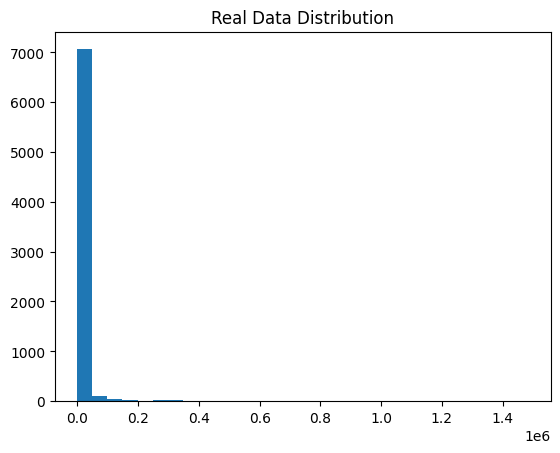

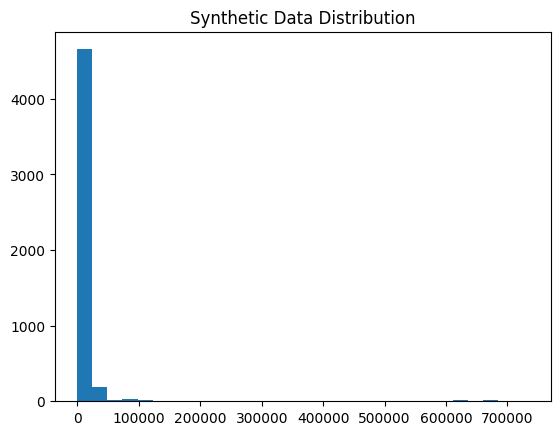

In [13]:
import matplotlib.pyplot as plt

plt.figure()
plt.hist(df['Value'], bins=30)
plt.title("Real Data Distribution")

plt.figure()
plt.hist(synthetic_data['Value'], bins=30)
plt.title("Synthetic Data Distribution")

**Check Categorical Distribution**

In [14]:
print("REAL Indicator Distribution")
print(df['Indicator'].value_counts(normalize=True).head())

print("\nSYNTHETIC Indicator Distribution")
print(synthetic_data['Indicator'].value_counts(normalize=True).head())

REAL Indicator Distribution
Indicator
Number of deaths in children aged <5 years, by cause                                                      0.113862
Deaths per 1 000 live births                                                                              0.096722
Distribution of causes of death among children aged < 5 years (%)                                         0.095225
Proportion of population with primary reliance on fuels and technologies for cooking, by fuel type (%)    0.082982
Population with primary reliance on fuels and technologies for cooking, by fuel type (in millions)        0.082982
Name: proportion, dtype: float64

SYNTHETIC Indicator Distribution
Indicator
Stunting prevalence among children under 5 years of age (% height-for-age <-2 SD), survey-based estimates    0.2216
Alcohol, recorded per capita (15+) consumption (in litres of pure alcohol), by beverage type                 0.1026
Distribution of causes of death among children aged < 5 years (%)             

**Save Trained Model (Important for Research Reproducibility)**

In [15]:
ctgan.save("ctgan_health_model.pkl")

files.download("ctgan_health_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

**How to Describe This in the Paper**



A Conditional Tabular Generative Adversarial Network (CTGAN) was implemented using the Synthetic Data Vault (SDV) framework to model the joint distribution of the health indicators dataset. The model was trained using 300 epochs with a batch size of 500 and learning rates of 0.0002 for both the generator and discriminator. Metadata was explicitly defined to distinguish between categorical and numerical variables, ensuring accurate modelling of mixed data types. Following training, the model was used to generate a synthetic dataset comprising 5,000 records, which was subsequently evaluated against the original dataset using statistical and distributional comparisons.